# Tutorial 1 · Chip 12: a coupled-qubit test chip, rebuilt in the Quantcore PDK

**Source.** The author's legacy design notebook `components/python/12.0 Coupled_chip_layout.ipynb` (Quantum Metal
`DesignPlanar`; Quantcore internal). The positions and options are transcribed in
`examples/designs/legacy/_legacy_b.py` (`D12_*` tables; spec `docs/designs/legacy/d12_coupled_chip.md`). The
design notebook `examples/designs/legacy/d12_coupled_chip.ipynb` builds the same chip in one cell; this tutorial
builds it **step by step** and runs the whole loop on it, including two real AEDT solves.

**What the chip is.** A 7.5 × 7.5 mm coupled-qubit test chip:
- one 20/12 µm feedline across the die centre with nine λ/4 readouts (10/6 µm, 4.3–6.3 mm long), each shorted 36 µm
  from the feedline centre-line (a 3 µm ground strip);
- nine `TransmonCross` Xmons, four above the line and five below;
- **Q1–Q2, a direct pair**: their cross-arm tips face each other across a 20 µm ground strip;
- **Q5–Q8–Q6, a tunable-coupler triple**: Q8 is a flux-tunable Xmon between Q5 and Q6, with its own readout;
- five flux lines (Q1, Q2, Q5, Q6, Q8) and five capacitive drive lines (Q0, Q2, Q3, Q4, Q7), each to its own 50 Ω
  launchpad.

**A Quantcore-PDK rebuild, not a replica.**

| | from the source | what the PDK changes (rule) |
|---|---|---|
| components | every Metal cell with the legacy options (`metal:` wrapper): `LaunchpadWirebondDriven`, `TransmonCross(FL)` | – |
| positions | legacy (0, 0) is the die centre: everything shifted by (+3.75, +3.75) mm | content centred in the die (it is) |
| pads | legacy launchpad positions (taper tips 950–1050 µm in) | **the PDK wins:** outer etch edge 100 µm from the die edge |
| junctions | external `JJ_grad` / `SQUID_grad` cells, no values | **trilayer** `Quantcore Junction` / `Quantcore Squid`, sized at the PDK nominal (R_n 45 kΩ) |
| cheese | none in the source | the PDK band (3 rows of 5 µm squares around the 3/0 keep-outs) |
| readouts | lengths, couplers 36 µm off the line, the shorts | hanger couplers pinned with `near=` (they stay put when the pads move) |
| values | the source has no qubit targets | out-of-margin values are **flagged** (DRC design warnings), never retuned |

Runtime ≈ 1 min (kept FEM results are loaded). With `RUN_FEM = True` add two Q3D solves (≈ 3 + 5 min) and two
workstation-sized eigenmode/EPR solves (section 10 explains how the groups were cut down after the first attempt
timed out at 20 min).

**`KLAYOUT_GUI`** (next to `LIVE`): `True` opens the KLayout window when it is not running (≈ 15–20 s the first time, with the layout and the Quantcore plugin), reopens it if you closed it, and brings it to the front on the first build; `False` only redraws a KLayout you already have open (klive).

**Dashboard** (`track.start("t01")` in the setup cell): every build, DRC, LOM run, FEM job (with its pass / Δ / mesh while AEDT runs) and feedback step is recorded into `build/t01/state.json`; `scripts\dashboard.cmd` in a terminal shows it live at http://127.0.0.1:8765/ (`track.stop()` switches the recording off).

In [1]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "examples" / "tutorials"))
import _tut as T
T.setup("t01")                                    # cwd = repo root; examples/designs(/legacy) importable
import _common as C                               # design-notebook helpers
import _legacy as L                               # PDK junction-rule helpers (legacy group)
import _legacy_b as LB                            # chip-12 tables transcribed from the legacy notebook
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

KLAYOUT_GUI = True                                # True: open / raise the KLayout window; False: redraw an open one only
LIVE = T.live_mode(gui=KLAYOUT_GUI)
from quantcore_circuits import track
TRACKING = track.start("t01")                     # dashboard (scripts\dashboard.cmd) follows build/t01
pdk = get_pdk()

Headless (QCC_LIVE=0): each build writes build/<name>.oas; pictures are headless KLayout snapshots.


### The FEM part in two stages, and its switches

The FEM part (sections 10 and 11) runs in two stages:

1. **Stage 1, the subset FEM (section 10).** `SIM_SUBSET` picks `(qubit, readout)` pairs, e.g. `[("Q1", "R1")]` (the
   default: Q1, its λ/4 and the stretch of feedline it hangs from, which the box cuts into 50 Ω ports) or
   `[("Q3", "R3"), ("Q5", "R5")]` (two boxes, solved one after the other). With them run Q1's own boxes: the
   eigenmodes `Q1_q` / `Q1_R1e` and the direct pair `Q1_Q2`. The check shows FEM values only — the convergence, the
   raw C-matrices and eigenmodes (f, Q, p_J), the FEM-filled capacitances next to their estimates. If they are sane
   and converged, go on.
2. **Stage 2, the whole LOM (section 11).** The subset values are filled into the **whole** netlist (every other
   branch keeps its estimate, `scope="auto"`), the LOM runs on the whole netlist (every qubit–readout pair, the direct
   pair's J), LOM and FEM are compared, and the readouts get their feedback → a revision, its DRC and its fab file.

**`FEM_WHOLE = True`** (opt-in, slow) also solves the whole chip (the built-in group `chip`, every pad a 50 Ω port)
and fills the netlist from it instead: Q3D ≈ 2–3 min at `FEM_FAST`; a whole-chip eigenmode (`WHOLE_ANALYSES`) takes
hours. `RUN_FEM` solves the jobs, one AEDT job at a time; `RESOLVE` re-solves jobs whose kept results match (after a
library fix, say); `FEM_FAST` and `AEDT_MODE` are explained in section 10.

In [2]:
SIM_SUBSET = [("Q1", "R1")]      # stage 1: (qubit, readout) pairs; [("Q3", "R3"), ("Q5", "R5")]: two boxes
FEM_WHOLE = False                # True (slow, opt-in): also solve the whole chip and fill the LOM from it (section 11)
WHOLE_ANALYSES = ["q3d_cmatrix"] # with FEM_WHOLE: Q3D ≈ 2–3 min; "eigenmode_epr": hours, > 30 GB
RUN_FEM = False                  # True (or a set of analyses): solve the jobs in AEDT, one at a time
RESOLVE = False                  # True (or a set of analyses): re-solve even when the kept results match
FEM_FAST = True                  # True: fast test settings (few passes, values not converged); False: converged settings
AEDT_MODE = "batch"              # "batch" (no window) | "gui" (a new AEDT window) | "attach" (yours)

## 1 · The PDK facts this chip uses

The full table is in Tutorial 0; the facts that matter here:

In [3]:
from quantcore_circuits.circuit.bridges import lj_from_rn, rn_from_lj

j = pdk.junction
T.md("\n".join([
    "| PDK fact | used for |", "|---|---|",
    f"| stack: {pdk.stack.substrate_material} {pdk.stack.substrate_height:g} µm, εr {pdk.stack.substrate_permittivity:g} "
    "| every capacitance estimate, the λ/4 lengths and both FEM jobs |",
    f"| pad rule: outer etch edge {pdk.frame.pad_edge:g} µm from the die edge | the 12 launchpads (`edge=\"auto\"`) |",
    f"| junction rule: R_n {j.rn_target_kohm[0]:g}–{j.rn_target_kohm[1]:g} kΩ, nominal {j.rn_nominal_kohm:g} kΩ → "
    f"L_J {lj_from_rn(j.rn_nominal_kohm * 1e3):.2f} nH | the nine junctions (the source gives no values) |",
    f"| qubit band {j.f_q_range_GHz[0]:g}–{j.f_q_range_GHz[1]:g} GHz | flagged, not enforced |",
    f"| cheese: {pdk.cheese.rows} rows × {pdk.cheese.size:g} µm squares, {pdk.cheese.gap:g} µm gaps | the source has "
    "none, so the PDK band (`cheese=\"auto\"`) |",
    f"| 3/0 keep-out: routes + {pdk.keepout.route_margin:g} µm, components + {pdk.keepout.component_margin:g} µm "
    "| fab export (section 12) |",
]))

| PDK fact | used for |
|---|---|
| stack: sapphire 650 µm, εr 10.25 | every capacitance estimate, the λ/4 lengths and both FEM jobs |
| pad rule: outer etch edge 100 µm from the die edge | the 12 launchpads (`edge="auto"`) |
| junction rule: R_n 40–50 kΩ, nominal 45 kΩ → L_J 6.73 nH | the nine junctions (the source gives no values) |
| qubit band 4–8 GHz | flagged, not enforced |
| cheese: 3 rows × 5 µm squares, 20 µm gaps | the source has none, so the PDK band (`cheese="auto"`) |
| 3/0 keep-out: routes + 10 µm, components + 24 µm | fab export (section 12) |

## 2 · The die and the frame

The legacy design is centred on (0, 0); `at(x, y)` moves a legacy coordinate into the Designer frame (die corner at
the origin). `name_chip` sets the device-ID text: the frame puts it at the bottom centre unless something sits there,
then on the first free side or slid along an edge.

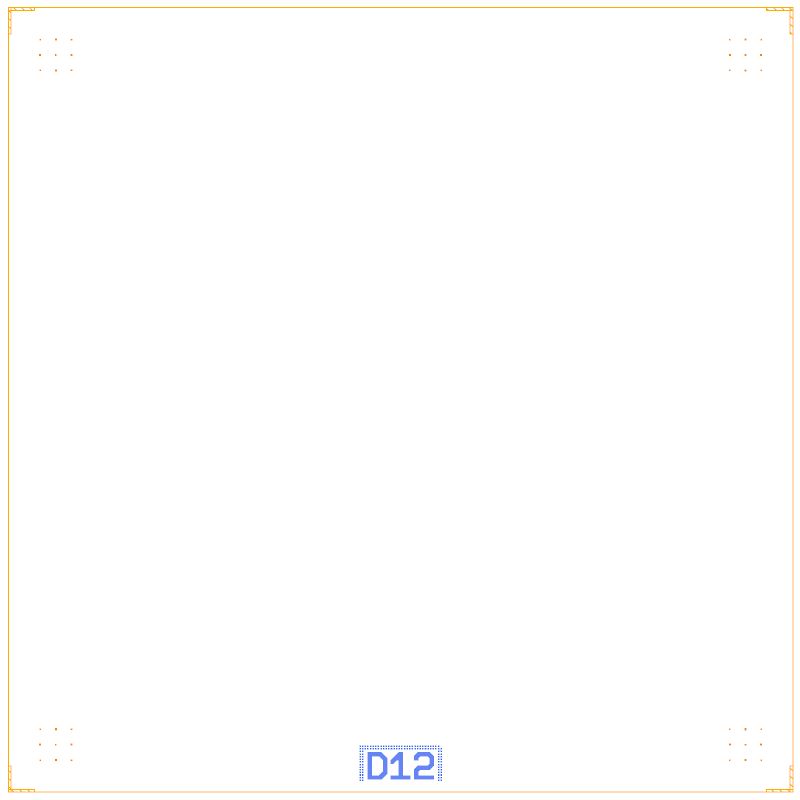

WindowsPath('examples/tutorials/img/t01_die.png')

In [4]:
X0 = Y0 = 3750                                    # legacy (0, 0) → die centre


def at(x, y):
    return (X0 + x, Y0 + y)


d = Designer("t01_chip12", box=(0, 0, 7500, 7500), chip={"name_chip": "D12"}, live=LIVE)
T.built(d)
T.snap(d, "die", size=(800, 800), width=320)

## 3 · Pads: twelve launchpads at the 100 µm rule

Two feed launchpads (400 × 400 µm, 20/12 µm trace) and ten 50 Ω line pads (400 × 300 µm, 10/5.75 µm trace), all
Quantum Metal `LaunchpadWirebondDriven` with the legacy options. Their port `tie` is where a route attaches; `in` is
the bond pad itself (left unconnected: it is the external port).

`edge="auto"` slides each pad perpendicular to its nearest die edge until its outer etch edge is 100 µm from it. The
legacy positions had the pad tapers ≈ 1 mm in; the table shows the result.

<metal:LaunchpadWirebondDriven P1_C ports=['in', 'tie']>


| pad | asked at (x, y) µm | outer etch edge → die edge (µm) |
|---|---|---|
| `P1_C` | (6450, 3750) | 100.0 |
| `P2_C` | (1050, 3750) | 100.0 |
| `LP_TB_00` | (2450, 950) | 100.0 |
| `LP_TB_01` | (3730, 950) | 100.0 |
| `LP_TB_02` | (5050, 950) | 100.0 |
| `LP_TB_10` | (2450, 6550) | 100.0 |
| `LP_TB_11` | (3730, 6550) | 100.0 |
| `LP_TB_12` | (5050, 6550) | 100.0 |
| `LP_LR_00` | (950, 1750) | 100.0 |
| `LP_LR_10` | (950, 5750) | 100.0 |
| `LP_LR_01` | (6550, 1750) | 100.0 |
| `LP_LR_11` | (6550, 5750) | 100.0 |

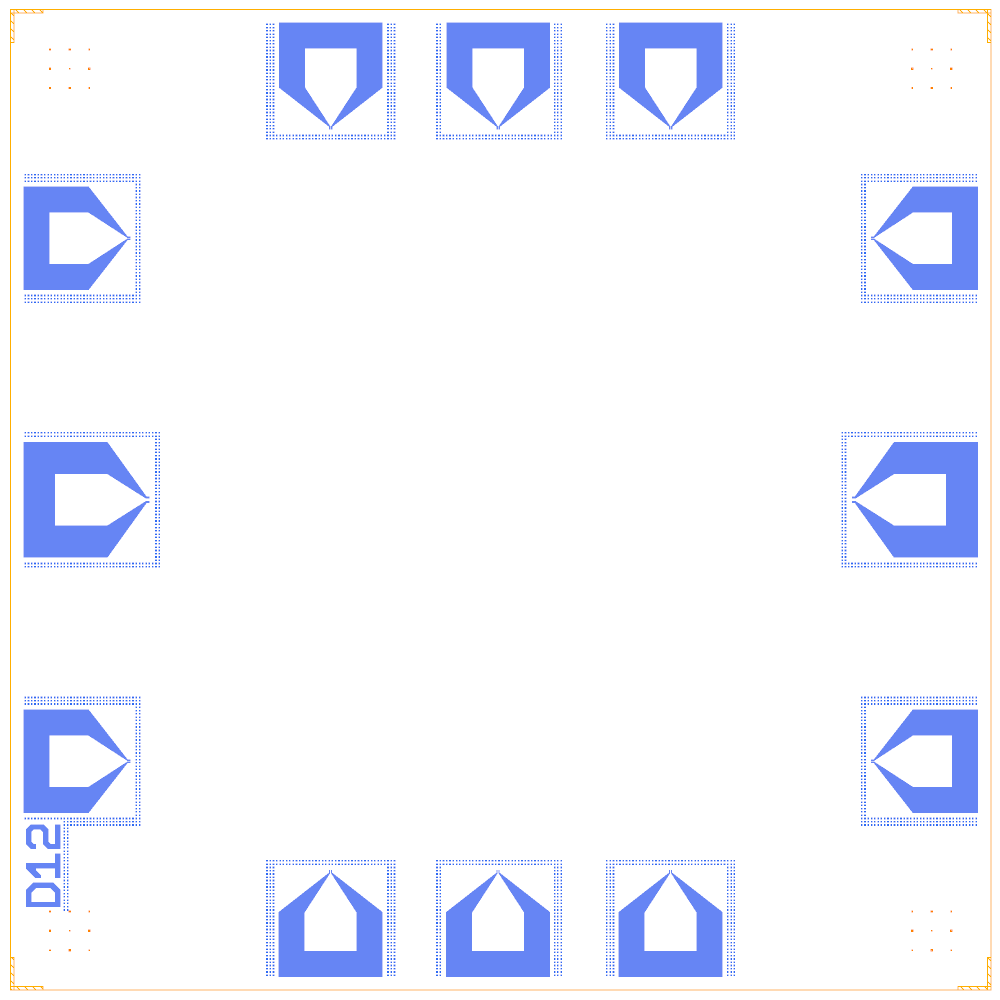

WindowsPath('examples/tutorials/img/t01_pads.png')

In [5]:
with d.batch():                                   # one rebuild for the twelve pads
    p1 = d.add("P1_C", "metal:LaunchpadWirebondDriven", at=at(2700, 0), rot=180, lead_length="20um", edge="auto",
               **LB.D12_FEED_LAUNCHPAD)
    p2 = d.add("P2_C", "metal:LaunchpadWirebondDriven", at=at(-2700, 0), rot=0, lead_length="20um", edge="auto",
               **LB.D12_FEED_LAUNCHPAD)
    pads = {n: d.add(n, "metal:LaunchpadWirebondDriven", at=at(x, y), rot=rot, edge="auto", **LB.D12_LINE_LAUNCHPAD)
            for n, (x, y, rot) in LB.d12_line_pads().items()}
print(p1)
T.md(T.pad_edges_md(d))
T.snap(d, "pads", size=(1000, 1000), width=400)

## 4 · The feedline

One 20/12 µm CPW between the two feed pads (`a=20, b=12`). It runs right to left (P1 → P2), so its "right" side is
the top half of the chip: that decides the hanger `side` below.

In [6]:
fl = d.route("cpw_main", p1.tie, p2.tie, a=20, b=12)
T.built(d)
print(f"feedline: {d.result.route_lengths()['cpw_main']:.0f} µm")

feedline: 5380 µm


## 5 · Components: nine Xmons with trilayer junctions

Each qubit is Quantum Metal's `TransmonCross` (`TransmonCrossFL` where it has a flux line), wrapped by `metal:`:
cross 220 × 50 µm in a 20 µm gap; claw `a` (150 µm, 6 µm gap) for the readout; a capacitive drive pad `bus_drive`
on five qubits; a flux line tip on five. Their ports: `a` (readout), `bus_drive`, `flux_line`, and `squid_a/b`
(where the junction attaches — not route ends).

**Junctions.** `junction_type="Quantcore Junction"` / `"Quantcore Squid"` draws the PDK trilayer cell on the
junction line (fingers 2/0 + 4/0, spacer 50/0 with the 51–53/0 gradient). The source gives no junction values, so
every qubit gets the PDK nominal R_n = 45 kΩ → L_J 6.73 nH (`L.lj_for_rn`). A SQUID gets the same *total* L_J:
each of its two junctions is 13.5 nH / 90 kΩ, and the PDK window (40–50 kΩ) judges the device's parallel R_n,
45 kΩ.

junction: {'Lj_nH': 6.7344, 'Cj_fF': 15.0} · R_n 45.0 kΩ (single) / 90.0 kΩ per SQUID junction
<metal:TransmonCrossFL Q2 ports=['a', 'bus_drive', 'flux_line', 'squid_a', 'squid_b']>


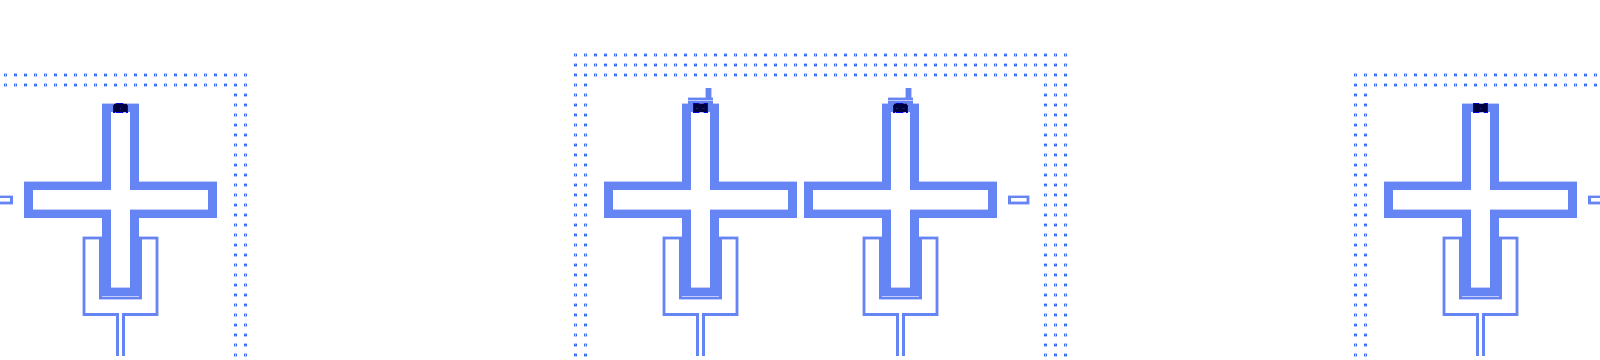

WindowsPath('examples/tutorials/img/t01_qubits_top.png')

In [7]:
JUNCTION = L.lj_for_rn(L.RN_NOMINAL_OHM)          # {"Lj_nH": 6.73, "Cj_fF": 15}: drawn L_J / C_J for the LOM
JJ = {"junction_type": "Quantcore Junction", "junction_params": {"lj_nH": JUNCTION["Lj_nH"]}}
SQ = {"junction_type": "Quantcore Squid", "junction_params": {"lj_nH": JUNCTION["Lj_nH"]}}
print("junction:", JUNCTION, f"· R_n {rn_from_lj(JUNCTION['Lj_nH']) / 1e3:.1f} kΩ (single) / "
      f"{rn_from_lj(2 * JUNCTION['Lj_nH']) / 1e3:.1f} kΩ per SQUID junction")

q = {}
with d.batch():
    for n, (x, y, flux, drive) in LB.D12_QUBITS.items():
        conn = {"a": dict(LB.D12_CLAW)}
        if drive:
            conn["bus_drive"] = dict(LB.D12_DRIVE_PAD, connector_location=drive)
        extra = {"fl_options": dict(LB.D12_FL_OPTIONS)} if flux else {}
        q[n] = d.add(n, "metal:TransmonCrossFL" if flux else "metal:TransmonCross", at=at(x, y),
                     rot=180 if y > 0 else 0, junction=JUNCTION, connection_pads=conn,
                     **(SQ if flux else JJ), **LB.D12_CROSS, **extra)
print(q["Q2"])
T.snap(d, "qubits_top", box=at(-2000, 1600) + at(2000, 2500), size=(1600, 360), width=760)

**The couplings no route carries.** Q1–Q2 (and Q5–Q8, Q8–Q6) couple through their facing arm tips, 60 µm apart
across a 20 µm ground strip. No route joins them, so the coupling is declared with `d.couple`: a rough screened
coplanar-strip estimate now (≈ 1.7 fF); the `Q1_Q2` FEM group (section 10) gives the real value by net name.

In [8]:
from quantcore_circuits.lom import estimates as est

C_ARM = round(est.coplanar_coupling(50, 220, 220, 60, est.substrate_eps(d.design.pdk), 0.3), 2)
for a, b in (("Q1", "Q2"), ("Q5", "Q8"), ("Q8", "Q6")):
    d.couple(f"C_{a}{b}", a, b, C_fF=C_ARM, note="arm tips 60 µm apart across a 20 µm ground strip (CPS × 0.3)")
print(f"C_arm = {C_ARM} fF")

C_arm = 1.67 fF


## 6 · Routes: nine λ/4 readouts, flux and drive lines

**Readouts.** Each runs from the claw `a` to a hanger on the feedline:

- `fl.hanger(near=(x, y), length=…)` centres the coupler at the feedline point nearest (x, y), here the legacy
  coupler centre. Hangers given by arclength `s=` would slide by however far the pad moved; `near=` pins them;
- `ground_gap=3`: the 3 µm ground strip between the coupler and the feedline (short end 36 µm from its centre-line);
- `end="short"`, `direction` (which end is shorted), `side` (above or below the line);
- `meander=<length>`: the legacy length, drawn as a KQC `Meander` on one vertical segment (`LB.d12_meander_x` picks
  the legacy meander axis where both jogs fit). `meander_direction=-1` would mirror it; `bend=False` would enter the
  coupler straight.

In [9]:
R = 60                                            # legacy fillet on the resonators
with d.batch():
    for n, (length, x_short, dirx, cpl, axis, y_row, y_jog) in LB.D12_RES.items():
        qn = "Q" + n[1:]
        x_q, sy = LB.D12_QUBITS[qn][0], (1 if LB.D12_QUBITS[qn][1] > 0 else -1)
        x_far, x_m = x_short + dirx * cpl, LB.d12_meander_x(n, R)
        if x_m == x_q:
            nodes = [(x_q, sy * y_row), (x_far, sy * y_row)]
        elif x_m == x_far:
            nodes = [(x_q, sy * y_jog), (x_far, sy * y_jog)]
        else:
            nodes = [(x_q, sy * y_jog), (x_m, sy * y_jog), (x_m, sy * y_row), (x_far, sy * y_row)]
        hanger = fl.hanger(near=at(x_short + dirx * cpl / 2, 0), length=cpl, side="right" if sy > 0 else "left",
                           ground_gap=3, direction="forward" if dirx > 0 else "backward", end="short")
        d.route(n, q[qn].a, hanger, meander=length, a=10, b=6, r=R, nodes=[at(*p) for p in nodes])
T.built(d)
T.md("| readout | drawn length (µm) | legacy length (µm) |\n|---|---|---|\n" + "\n".join(
    f"| {n} | {d.result.route_lengths()[n]:.1f} | {LB.D12_RES[n][0]} |" for n in LB.D12_RES))

| readout | drawn length (µm) | legacy length (µm) |
|---|---|---|
| R0 | 5493.0 | 5493 |
| R1 | 6262.0 | 6262 |
| R2 | 6140.0 | 6140 |
| R3 | 4638.0 | 4638 |
| R4 | 4475.0 | 4475 |
| R5 | 5200.0 | 5200 |
| R6 | 5132.0 | 5132 |
| R7 | 5690.0 | 5690 |
| R8 | 4300.0 | 4300 |

**Flux and drive lines.** 10/6 µm CPWs from each line pad's `tie` to the qubit's `flux_line` or `bus_drive` port,
through the legacy `RoutePathfinder` corner points as waypoints; bends r = 50 µm (the legacy corners sit 100 µm from
the pins). The pads moved out to the edge, so the first straight of each line is simply longer.

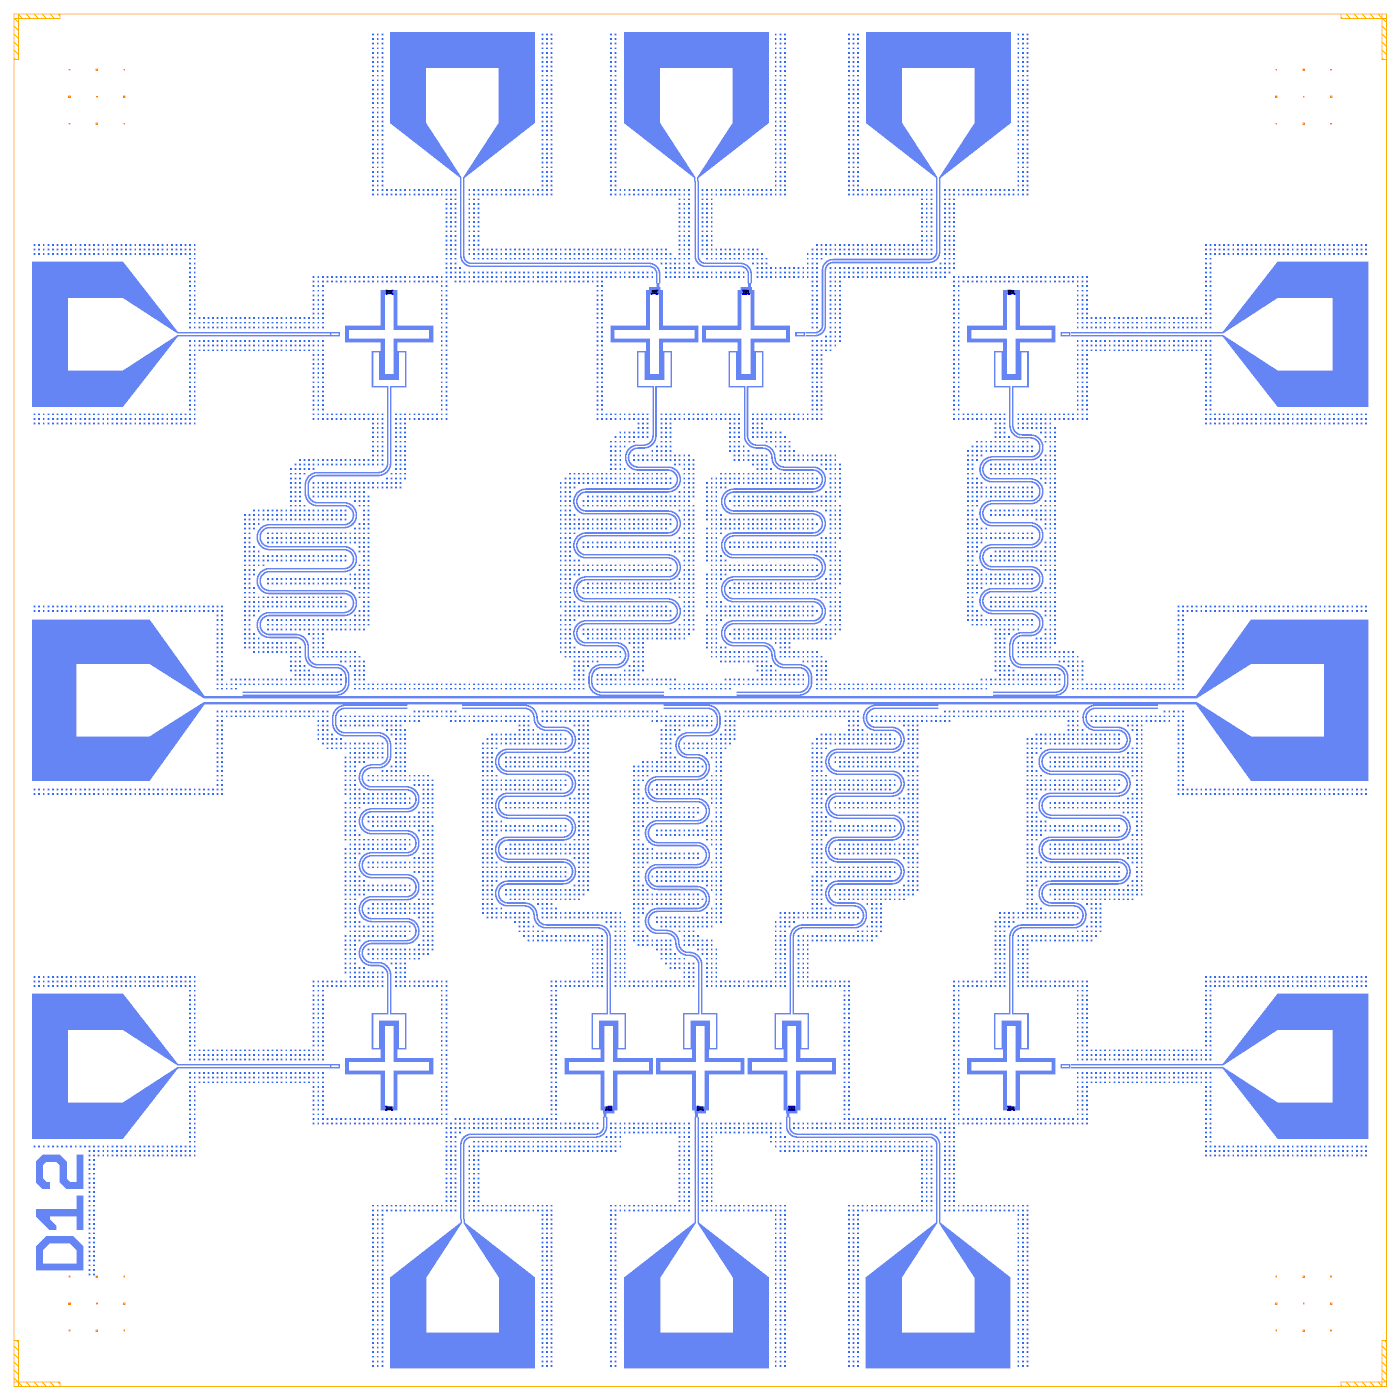

WindowsPath('examples/tutorials/img/t01_chip.png')

In [10]:
with d.batch():
    for pad, (qn, pin, pts) in LB.D12_LINES.items():
        d.route(f"{'FLX' if pin == 'flux_line' else 'DRV'}_{qn}", pads[pad].tie, q[qn][pin], a=10, b=6, r=50,
                nodes=[at(*p) for p in pts])
T.snap(d, "chip", size=(1400, 1400), width=600)

## 7 · DRC

Three severities:

- **errors** — the chip is wrong (overlaps, crossings without a bridge, routes outside the die, opens/shorts against
  the declared netlist). Must be zero;
- **warnings** — worth a look, often expected: here `dangling_port` on every launchpad's `in` (the bond pad itself,
  the external port) and on each qubit's `squid_a/b` (junction attachment points, not route ends);
- **PDK design warnings** — values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
  never changed. None here: the pads are at 100 µm, every device R_n is 45 kΩ, and the claws clear the cross arms
  (section 12 shows one that does not).

`C.pdk_report(d)` sums up the conformance checks: cheese source, centring, junction types, design warnings.

In [11]:
rep = T.drc(d)
T.md(T.drc_md(rep))
T.md(C.pdk_report(d))

**DRC clean** — 0 errors, 30 warnings, 0 PDK design warnings

| severity | rule | count | example |
|---|---|---|---|
| warning | `dangling_port` | 30 | LP_LR_00.in is not connected (no route or snap)<br>LP_LR_01.in is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 4, Quantcore Squid × 5 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to nodes, each route
becomes a conductor or a resonator.

- the feedline is one node `cpw_main` with a 50 Ω port at each feed pad and nine `HANGER` κ elements;
- each qubit: island node (C and JJ / SQUID to ground) — C_g — claw node `Qn.a` — λ/4 `TLres` to ground;
- a drive line joins its pad's 50 Ω port to the qubit's `bus_drive` node; a flux line ends on `control:flux`;
- the declared couplings `C_Q1Q2`, `C_Q5Q8`, `C_Q8Q6` join the facing islands.

The whole netlist has 24 nodes; below, the direct pair with its readouts.

In [12]:
lb = d.lom()
print(C.lom_summary(lb))
C.show_netlist(d.lom(select=["Q1", "Q2", "R1", "R2"]))

{'nodes': 24, 'branches': 74, 'controls': 5, 'unconnected': 12}


**7 nodes · 16 branches · 0 controls · 1 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `Q1` | `Q1.island` |
| `Q1.a` | `Q1.a` |
| `Q2` | `Q2.island` |
| `Q2.a` | `Q2.a` |
| `Q2.bus_drive` | `Q2.bus_drive` |
| `cpw_main` | `cpw_main` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_Q1` | C | `Q1` – `gnd` | 120 fF |
| `J_Q1` | SQUID | `Q1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_a` | C | `Q1` – `Q1.a` | 5.2 fF |
| `Cc_Q1_a` | C | `Q1.a` – `gnd` | 121 fF |
| `C_Q2` | C | `Q2` – `gnd` | 120 fF |
| `J_Q2` | SQUID | `Q2` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_a` | C | `Q2` – `Q2.a` | 5.2 fF |
| `Cc_Q2_a` | C | `Q2.a` – `gnd` | 121 fF |
| `Cg_Q2_bus_drive` | C | `Q2` – `Q2.bus_drive` | 0.09 fF |
| `Cc_Q2_bus_drive` | C | `Q2.bus_drive` – `gnd` | 11.8 fF |
| `C_C_Q1Q2` | C | `Q1` – `Q2` | 1.67 fF |
| `R1` | TLres | `Q1.a` – `gnd` | lambda/4, 6262 µm, 5.032 GHz |
| `Port_cpw_main` | R | `cpw_main` – `gnd` | 25 Ω |
| `K_R1` | HANGER | `Q1.a` – `cpw_main` | κ 0.257 MHz (L 400 µm) |
| `R2` | TLres | `Q2.a` – `gnd` | lambda/4, 6140 µm, 5.132 GHz |
| `K_R2` | HANGER | `Q2.a` – `cpw_main` | κ 0.273 MHz (L 400 µm) |

**Unconnected ports:** `Q2.bus_drive`

## 9 · LOM simulation against the targets

The source has no qubit targets. Its readout lengths were drawn for a *bare* λ/4 (no claw), so the bare-line
frequency of each legacy length is the readout target here; the PDK band (4–8 GHz) is the qubit check.

**(a) Each qubit with its readout** (the feedline as a 25 Ω load): QuCat normal modes and κ, then QuTiP dressed
values; targets in brackets.

In [13]:
from quantcore_circuits.circuit.bridges import tl_resonator

d.targets(**{n: {"f_GHz": round(tl_resonator(LB.D12_RES[n][0], 10, 6)["f_GHz"], 4)} for n in LB.D12_RES})
pairs = {f"{qn}+R{qn[1:]}": [qn, f"R{qn[1:]}"] for qn in LB.D12_QUBITS}
results = C.simulate_groups(d, pairs)
T.md(C.groups_md(results, d.data["targets"]))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q0+R0 | Q0 | 5.0591 | -196.9 | R0 | 4.9357 (5.7361) | 0.411 | 64.7 |
| Q1+R1 | Q1 | 5.0411 | -146 | R1 | 4.4242 (5.0317) | 0.153 | -1.64 |
| Q2+R2 | Q2 | 5.0401 | -145.2 | R2 | 4.5015 (5.1317) | 0.161 | -2.37 |
| Q3+R3 | Q3 | 5.0325 | -146 | R3 | 5.7585 (6.7936) | 0.323 | -1.59 |
| Q4+R4 | Q4 | 5.0331 | -146.4 | R4 | 5.937 (7.041) | 0.354 | -1.16 |
| Q5+R5 | Q5 | 5.0248 | -135.7 | R5 | 5.226 (6.0594) | 0.165 | -11 |
| Q6+R6 | Q6 | 5.0277 | -139.6 | R6 | 5.283 (6.1396) | 0.216 | -7.82 |
| Q7+R7 | Q7 | 5.046 | -124.6 | R7 | 4.8085 (5.5375) | 0.192 | -22.7 |
| Q8+R8 | Q8 | 5.0352 | -146.8 | R8 | 6.1513 (7.3276) | 0.221 | -0.86 |

Every Xmon lands at ≈ 5.0 GHz (inside the PDK band) with α ≈ −145 MHz. The claw adds ≈ 125 fF at each readout's open
end, so the loaded readouts sit 0.6–1.2 GHz below their bare λ/4 — the legacy lengths were simulated without the
claws. Q0/R0 come out nearly degenerate (they hybridise) and Q7/R7 are close: a design decision for the user, not
something this rebuild retunes.

**(b) The direct pair Q1–Q2.** With the same junction on both they are resonant and hybridise (each mode is half Q1,
half Q2); the splitting is 2J. `C.exchange_coupling` sweeps Q2's L_J through the crossing and fits the splitting.
Detuning Q2 (L_J 7.4 nH) separates them and gives the static ZZ.

In [14]:
pair = C.simulate_groups(d, {"Q1+Q2": ["Q1", "Q2"]})
T.md(C.modes_md(pair["Q1+Q2"]))
J = C.exchange_coupling(d, ["Q1", "Q2"], "Q1", "Q2")
T.md(C.exchange_md({"Q1-Q2": J}))
detuned = C._simulate_model(d.lom(select=["Q1", "Q2"]).model, d.design, 2, {"J_Q2": 7.4})
print(f"Q2 detuned (L_J 7.4 nH): f_Q1 {detuned.params['Q1.f_q_GHz']:.4f}, f_Q2 {detuned.params['Q2.f_q_GHz']:.4f} GHz")
T.md(C.zz_md({"Q1+Q2, Q2 detuned": detuned}))

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q2 | qubit | 5.1220 | 0 | 67.6 | J_Q2 0.51, J_Q1 0.49 |
| Q1 | qubit | 5.1828 | 0 | 69.2 | J_Q1 0.51, J_Q2 0.49 |

| pair | f_a (GHz) | f_b (GHz) | J (MHz) | target J (MHz) | ZZ (kHz) |
|---|---|---|---|---|---|
| Q1-Q2 | 5.0413 | 4.9822 | 29.5 | – | – |

Q2 detuned (L_J 7.4 nH): f_Q1 5.0160, f_Q2 4.7702 GHz


| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| Q1+Q2, Q2 detuned | Q1-Q2 | -1.12e+04 | yes | no |

J ≈ 30 MHz comes from the rough 1.7 fF arm estimate; the Q1_Q2 C-matrix job replaces it. With α ≈ −140 MHz and J
that large, the static ZZ of the detuned pair is in the MHz range — the reason Q8 sits between Q5 and Q6 as a tunable
coupler.

**(c) The tunable-coupler triple Q5–Q8–Q6** at zero flux (all three resonant): three hybridised modes.

In [15]:
tri = C.simulate_groups(d, {"Q5–Q8–Q6": ["Q5", "Q8", "Q6"]}, max_modes=3)
T.md(C.modes_md(tri["Q5–Q8–Q6"]))

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q8 | qubit | 5.0932 | 0 | 66.8 | J_Q8 0.67, J_Q5 0.17, J_Q6 0.17 |
| Q5 | qubit | 5.1529 | 0 | 68.4 | J_Q5 0.50, J_Q6 0.50 |
| Q6 | qubit | 5.1836 | 0 | 46.1 | J_Q5 0.33, J_Q8 0.33, J_Q6 0.33 |

> **Simulation PC (32 GB+ RAM).** The cells below solve the FEM jobs of the chip in AEDT: the Q3D groups, the split eigenmode groups (`Q1_q`, `Q1_R1e`) at converged settings, and, if you set `WHOLE_ANALYSES`, the whole-chip eigenmode (more than 30 GB, hours). On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

## 10 · FEM stage 1: the subset FEM and its check

Sim groups (`d.sim_group`) select what goes into each FEM job:

| group | analyses | box | gives |
|---|---|---|---|
| `Qn_Rn` (nine) | `q3d_cmatrix` (+ `eigenmode_epr` for a server) | the qubit + 300 µm (Q3D cuts the readout at the claw) | C_island, C_g, C_claw |
| `Q1_q` | `eigenmode_epr` | Q1 + 150 µm; the readout and the flux lines are cut by the box and terminated in 50 Ω (`ports={"R1": "edge"}`) | the qubit mode: f_q, α, p_J (pyEPR) |
| `Q1_R1e` | `eigenmode_epr` | Q1 + the whole 6.3 mm readout + 100 µm (cuts the feedline: 50 Ω at both ends) | f_q, f_r, χ, κ (pyEPR, mode Q) |
| `Q1_Q2` | `q3d_cmatrix` | both qubits + 300 µm; their readouts are selected so the build cuts them at the claws (named nets, not floating stubs) | the arm-to-arm C that `d.couple` estimates → J |
| `Q5_Q8_Q6` | `q3d_cmatrix` | the triple + 300 µm | the tunable-coupler capacitances |

**Why the eigenmode groups are split.** On 2026-11-03 the eigenmode/EPR job of `Q1_R1` (the qubit, its whole
readout and 300 µm, a 1.3 × 2.9 mm box) did not finish within 20 min on this workstation (hf3d ≈ 10 GB at 12 passes).
`Q1_q` keeps only the qubit (a 0.8 × 1.0 mm box; the 150 µm margin puts the box edge on a straight
section of the readout — where it cuts a bend the 50 Ω port gets no polygon and the builder warns): the readout leaves the box as a matched 50 Ω line, so the job
gives the qubit's own mode (f_q, α, p_J) without the readout's dispersive shift. `Q1_R1e` keeps the readout with a
100 µm margin and a coarser stop (max ΔF 0.5 %, 10 passes) for f_r and χ. Neither includes Q2's junction: Q2's island
sits 60 µm from Q1's arm, so it is in the box as a floating conductor (its junction is not simulated).

"Send" = export: `C.export_sims` (`examples/designs/_common.py`) writes `build/jobs/<design>_<group>_<analysis>/` — the KQC
geometry (no cheese; airbridges dropped by default), ports, net names, AEDT scripts. **`RUN_FEM = True`** then solves
the five jobs below with `sim_tools.hfss.solve_job`, one at a time: each in a *new* non-graphical AEDT 2024 R1 batch
process (it never attaches to an AEDT window you have open, and KQC's `run_pyepr_t1_estimate.py`, which would quit
it, is not used). The results are copied to `examples/tutorials/fem/` so the next section works without AEDT.

**`AEDT_MODE`** (next to `RUN_FEM`): `"batch"` solves in a new non-graphical AEDT; `"gui"` opens a new AEDT window and leaves it open, so you watch the mesh, the convergence and the fields; `"attach"` runs inside the AEDT window you already have open (or opens one) and leaves the project there. Every mode prints a progress line (step, pass, mesh, ΔF / ΔS / ΔC) every 30 s, so a stuck run is visible; on a timeout only what qcc started is stopped.

**`FEM_FAST`** (first line of the next cell; it also exports the **whole chip** as one Q3D job, the built-in group `chip`, default `True`): every job is exported with the library's fast test settings (`sim_tools.export.FAST_SETTINGS`: Q3D 2 % / ≤ 8 passes, eigenmode ΔF 1 % / ≤ 3 passes (memory-bound here), driven ΔS 0.05 / ≤ 6 passes, mesh seeds × 3 (none given: a 40 / 30 µm gap seed for eigenmode / driven), sweeps ≤ 10 001 points), so the whole chain (solve → keep → bring back → feedback → re-solve) runs in minutes. The values are not converged; they move with the design. `False` exports the settings as written for a production run (kept results of a full solve also stand in for a fast re-run of the same design).

The subset check after the solve shows FEM values only (`T.subset_check`); section 11 fills them into the whole
netlist. The whole-chip FEM (`chip`, every qubit, readout, feedline and control line as named nets) is opt-in:
`FEM_WHOLE = True`.

In [16]:
FEM_FAST = T.fem_fast(FEM_FAST)                   # the switch from the top: fast test settings, or as below
for n in LB.D12_QUBITS:
    d.sim_group(f"{n}_R{n[1:]}", [n, f"R{n[1:]}"], margin_um=300, analyses=["q3d_cmatrix", "eigenmode_epr"])
d.sim_group("Q1_q", ["Q1"], margin_um=150, analyses=["eigenmode_epr"], ports={"R1": "edge"},
            settings={"eigenmode_epr": {"n_modes": 2, "min_frequency": 3.0, "max_delta_f": 0.2, "maximum_passes": 14}})
d.sim_group("Q1_R1e", ["Q1", "R1"], margin_um=100, analyses=["eigenmode_epr"],
            settings={"eigenmode_epr": {"n_modes": 3, "min_frequency": 3.5, "max_delta_f": 0.5, "maximum_passes": 10}})
d.sim_group("Q1_Q2", ["Q1", "Q2", "R1", "R2"], margin_um=300, analyses=["q3d_cmatrix"])   # readouts cut: claws = nets
d.sim_group("Q5_Q8_Q6", ["Q5", "Q8", "Q6", "R5", "R8", "R6"], margin_um=300, analyses=["q3d_cmatrix"])
# SIM_SUBSET → its sim groups ([("Q1", "R1")] is the group Q1_R1 above; "whole" → the built-in group "chip")
SUBG = (T.sim_subset(d, SIM_SUBSET, name="_".join(f"{q}_{r or 'R' + q[1:]}" for q, r in SIM_SUBSET),
                     margin_um=300, analyses=["q3d_cmatrix", "eigenmode_epr"]) if SIM_SUBSET else [])
DESIGN = d.save(T.DESIGNS / "t01_chip12.json")
print("saved", DESIGN)
jobs = C.export_sims(DESIGN, [g for g in d.data["sim_groups"] if g not in ("Q1_q", "Q1_R1e")], "q3d_cmatrix")
jobs_eig = C.export_sims(DESIGN, ["Q1_q", "Q1_R1e"], "eigenmode_epr")
T.md(C.jobs_md({g: jobs[g] for g in ("Q1_R1", "Q1_Q2")}) + "\n" + C.jobs_md(jobs_eig).split("\n", 2)[2])
print(f"{len(jobs)} Q3D jobs + {len(jobs_eig)} eigenmode jobs in build/jobs/")

FEM_FAST: jobs are exported with the fast test settings (q3d_cmatrix percent_error 2, maximum_passes 8, minimum_passes 1; hfss_driven max_delta_s 0.05, maximum_passes 6, minimum_passes 1; eigenmode_epr max_delta_f 1, maximum_passes 3, minimum_passes 1); values are not converged


**SIM_SUBSET = [('Q1', 'R1')]** → 1 box(es); each is rendered and simulated on its own, and its values fill only these components of the whole-chip netlist:

| group (box) | qubits | readout chain | buses in | buses cut at the qubit | feedline (cut by the box) |
|---|---|---|---|---|---|
| `Q1_R1` | Q1 | Q1: R1 | – | – | cpw_main |

saved examples\tutorials\designs\t01_chip12.json


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1_R1 | `build/jobs/t01_chip12_Q1_R1_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `Q1.a`<br>3 · edge · `FLX_Q1`<br>4 · edge · `FLX_Q2` | `Q1.island`, `Q1.a` |
| Q1_Q2 | `build/jobs/t01_chip12_Q1_Q2_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · junction · `Q2.junction`<br>3 · waveguide · `Q1.a`<br>4 · waveguide · `Q2.a`<br>5 · edge · `DRV_Q2`<br>6 · edge · `FLX_Q1`<br>7 · edge · `FLX_Q2` | `Q1.island`, `Q2.island`, `Q1.a`, `Q2.a`, `Q2.bus_drive` |
| Q1_q | `build/jobs/t01_chip12_Q1_q_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `FLX_Q1`<br>3 · edge_lumped · `FLX_Q2`<br>4 · edge_lumped · `FLX_Q2`<br>5 · edge_lumped · `R1` | `Q1.island`, `FLX_Q1`, `FLX_Q2`, `FLX_Q2#2`, `R1` |
| Q1_R1e | `build/jobs/t01_chip12_Q1_R1e_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `FLX_Q1`<br>3 · edge_lumped · `cpw_main`<br>4 · edge_lumped · `cpw_main` | `Q1.island`, `FLX_Q1`, `cpw_main`, `cpw_main#2` |

11 Q3D jobs + 2 eigenmode jobs in build/jobs/


In [17]:
# RUN_FEM, RESOLVE, AEDT_MODE: the switches at the top (SIM_SUBSET cell)
def solve(job, timeout):
    return T.solve_or_load(job, RUN_FEM, aedt=AEDT_MODE, timeout=timeout, force=RESOLVE)


keep_q3d = solve(jobs["Q1_R1"][0], 900)           # ≈ 1–2.5 min
keep_pair = solve(jobs["Q1_Q2"][0], 1200)          # ≈ 1–5 min
keep_q = solve(jobs_eig["Q1_q"][0], 1800)          # the qubit mode
keep_eig = solve(jobs_eig["Q1_R1e"][0], 2400)      # qubit + readout, coarse stop
keep_sub = {g: keep_q3d if g == "Q1_R1" else solve(jobs[g][0], 900) for g in SUBG}   # the SIM_SUBSET boxes
# the subset check, FEM only: convergence, raw C-matrices / eigenmodes (f, Q, p_J), the filled C next to the estimates
CHECK = T.subset_check({**{f"{g} · q3d": k for g, k in keep_sub.items()}, "Q1_Q2 · q3d": keep_pair,
                        "Q1_q · eigenmode": keep_q, "Q1_R1e · eigenmode": keep_eig}, d.lom().model, DESIGN)

t01_chip12_Q1_R1_q3d_cmatrix: the kept results were solved for another revision of this job (design hash or settings differ); they are shown as they are — re-solve with RUN_FEM = True
t01_chip12_Q1_Q2_q3d_cmatrix: the kept results were solved for another revision of this job (design hash or settings differ); they are shown as they are — re-solve with RUN_FEM = True
t01_chip12_Q1_q_eigenmode_epr: the kept results were solved for another revision of this job (design hash or settings differ); they are shown as they are — re-solve with RUN_FEM = True
t01_chip12_Q1_R1e_eigenmode_epr: the kept results were solved for another revision of this job (design hash or settings differ); they are shown as they are — re-solve with RUN_FEM = True


| analysis | passes | tets (last) | criterion | last Δ / target | converged | wall time (s) |
|---|---|---|---|---|---|---|
| Q1_R1 · q3d | 8 | 11402 | Delta % | 1.24 / 2.0 | False | 60.6 |
| Q1_Q2 · q3d | 8 | 9220 | Delta % | 1.33 / 2.0 | False | 41.1 |
| Q1_q · eigenmode | 3 | 50812 | Max Delta Freq. % | 0.591 / 1.0 | True | 123.6 |
| Q1_R1e · eigenmode | 3 | 164948 | Max Delta Freq. % | 1.67 / 1.0 | False | 276.8 |

Q3D C-matrix of `t01_chip12_Q1_R1_q3d_cmatrix` (2024.1.0, 60.6 s; Maxwell form, fF):

| net | `Q1.island` | `Q1.a` |
|---|---|---|
| `Q1.island` | 121.431 | -10.883 |
| `Q1.a` | -10.883 | 111.388 |

Q3D C-matrix of `t01_chip12_Q1_Q2_q3d_cmatrix` (2024.1.0, 41.1 s; Maxwell form, fF):

| net | `Q1.island` | `Q2.island` | `Q1.a` | `Q2.a` | `Q2.bus_drive` |
|---|---|---|---|---|---|
| `Q1.island` | 119.227 | -1.153 | -10.694 | -0.216 | -0.002 |
| `Q2.island` | -1.153 | 118.853 | -0.218 | -10.712 | -0.092 |
| `Q1.a` | -10.694 | -0.218 | 108.847 | -0.101 | -0.001 |
| `Q2.a` | -0.216 | -10.712 | -0.101 | 108.755 | -0.007 |
| `Q2.bus_drive` | -0.002 | -0.092 | -0.001 | -0.007 | 6.724 |

Eigenmodes of `t01_chip12_Q1_q_eigenmode_epr` (2024.1.0, 123.6 s):

| mode | f linear (GHz) | Q | p_J | f dressed, pyEPR (GHz) | self-Kerr χ_mm (MHz) |
|---|---|---|---|---|---|
| 1 | 4.8791 | 970.7 | 0.9876 | 4.7564 | -126.9 |
| 2 | 15.5763 | 3.032e+05 | 0.0000 | 15.5763 | 0.0 |

Cross-Kerr (dispersive shift) χ₁₂ = 0.000 MHz (pyEPR, numerical diagonalisation).

Convergence: 3 passes, 50812 tets, last Max Delta Freq. % 0.59119 (target 1.0), converged: True.

Eigenmodes of `t01_chip12_Q1_R1e_eigenmode_epr` (2024.1.0, 276.8 s):

| mode | f linear (GHz) | Q | p_J | f dressed, pyEPR (GHz) | self-Kerr χ_mm (MHz) |
|---|---|---|---|---|---|
| 1 | 4.4486 | 1.573e+04 | 0.0409 | 4.4421 | -1.0 |
| 2 | 4.8344 | 2.344e+05 | 0.9469 | 4.7212 | -96.3 |
| 3 | 13.5232 | 4624 | 0.0002 | 13.5231 | 0.0 |

Cross-Kerr (dispersive shift) χ₁₂ = -26.451 MHz (pyEPR, numerical diagonalisation).

Convergence: 3 passes, 164948 tets, last Max Delta Freq. % 1.6658 (target 1.0), converged: False.

**FEM-filled capacitances of the simulated components** (the other branches keep their estimates):

| branch | nodes | estimate | FEM | from |
|---|---|---|---|---|
| `C_Q1` | Q1 – gnd | 120 | 110.5 | `t01_chip12_Q1_R1_q3d_cmatrix` |
| `Cg_Q1_a` | Q1 – Q1.a | 5.2 | 10.88 | `t01_chip12_Q1_R1_q3d_cmatrix` |
| `Cc_Q1_a` | Q1.a – gnd | 121 | 86.11 | `t01_chip12_Q1_R1_q3d_cmatrix` |
| `C_Q2` | Q2 – gnd | 120 | 106.7 | `t01_chip12_Q1_Q2_q3d_cmatrix` |
| `Cg_Q2_a` | Q2 – Q2.a | 5.2 | 10.71 | `t01_chip12_Q1_Q2_q3d_cmatrix` |
| `Cc_Q2_a` | Q2.a – gnd | 121 | 83.33 | `t01_chip12_Q1_Q2_q3d_cmatrix` |
| `Cg_Q2_bus_drive` | Q2 – Q2.bus_drive | 0.09 | 0.09232 | `t01_chip12_Q1_Q2_q3d_cmatrix` |
| `Cc_Q2_bus_drive` | Q2.bus_drive – gnd | 11.8 | 6.621 | `t01_chip12_Q1_Q2_q3d_cmatrix` |
| `C_C_Q1Q2` | Q1 – Q2 | 1.67 | 1.153 | `t01_chip12_Q1_Q2_q3d_cmatrix` |

**9** branches filled from FEM; **40** kept their estimates (38 outside the subset, e.g. `C_Q0`, `Cg_Q0_a`, `Cc_Q0_a`, `Cg_Q0_bus_drive`, `Cc_Q0_bus_drive`, `C_Q3`).
- `t01_chip12_Q1_R1_q3d_cmatrix` (group `Q1_R1`, q3d_cmatrix): 3 branches; scope Q1, R1
- `t01_chip12_Q1_Q2_q3d_cmatrix` (group `Q1_Q2`, q3d_cmatrix): 9 branches; scope Q1, Q2, R1, R2

**Look at these before the whole chip:** if the passes converged (or Δ sits near its target), the capacitances are positive and near their estimates and the qubit mode has p_J ≈ 1, go on and render and simulate the whole chip (stage 2). If not, change the mesh / settings here first: a subset solves in minutes.

> **Simulation PC (32 GB+ RAM).** The cells below fill the whole 9-qubit LOM from the solved subsets and compare LOM with FEM (the pair J and the tunable-coupler capacitances); they need fresh converged FEM results. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

## 11 · FEM stage 2: the subset values in the whole LOM

`fill(d.lom().model, DESIGN, FILL_Q3D)` fills the branches the stage-1 Q3D jobs simulated (`Q1_R1`, the `SIM_SUBSET`
boxes, `Q1_Q2`: Q1's island, claw and C_g, Q2's, the arm-to-arm C); every other branch keeps its estimate (and says
so). The LOM then runs on that **whole** netlist, pair by pair (QuCat on all nine qubits at once is far too slow):
each qubit with its readout (f_q, α, f_r, χ), next to the component estimates of section 9, and the eigenmode / pyEPR
f_q of Q1 as the FEM reference.

**The whole-chip FEM is opt-in (`FEM_WHOLE = True`; slow):**

| analysis | gives | on this workstation (FEM_FAST) |
|---|---|---|
| `q3d_cmatrix` | one C-matrix of the whole chip → fills every branch | 139 s, < 4 GB (2026-11-13) |
| `eigenmode_epr` | 18 modes (9 qubits, 9 readouts), p_J, pyEPR | not run here: expect several 10⁵ tets at pass 1, > 30 GB (swapping) and hours |

In [18]:
import json
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.sim_tools import build_simulation, export_job

WHOLE_SETTINGS = {"q3d_cmatrix": {}, "eigenmode_epr": {"n_modes": 18, "min_frequency": 3.5}}
WHOLE_TIMEOUT = {"q3d_cmatrix": 2400, "eigenmode_epr": 8 * 3600}   # s


def send_whole(a):
    """Export the whole chip (built-in group "chip") → build/jobs/t01_chip12_chip_<a>."""
    return export_job(build_simulation(DESIGN, "chip", a), f"build/jobs/{d.design.name}_chip_{a}", overwrite=True,
                      **WHOLE_SETTINGS[a])


wkeep = ({a: T.solve_or_load(send_whole(a), RUN_FEM, force=RESOLVE, aedt=AEDT_MODE, timeout=WHOLE_TIMEOUT[a])
          for a in WHOLE_ANALYSES} if FEM_WHOLE else {})
if wkeep:
    T.md(T.convergence_md({f"chip · {a}": k for a, k in wkeep.items()}))
keep_chip = wkeep.get("q3d_cmatrix")
# the jobs that fill the whole netlist: the whole chip with FEM_WHOLE, else the stage-1 subset Q3D jobs
FILL_Q3D = [keep_chip] if keep_chip else [k for k in dict.fromkeys([*keep_sub.values(), keep_pair]) if k]
FROM = "whole-chip" if keep_chip else "subset"
ON_FEM, chip_rows = {}, []
if FILL_Q3D:
    filled_w = fill(d.lom().model, DESIGN, FILL_Q3D)   # the whole netlist; unsimulated branches keep estimates
    T.md(T.subset_md(filled_w, rows=12))
    for qn in LB.D12_QUBITS:                       # the LOM on the filled whole netlist, pair by pair
        rn = f"R{qn[1:]}"
        a = results[f"{qn}+{rn}"].params           # the component estimates (section 9)
        b = ON_FEM[qn] = simulate(fill(d.lom(select=[qn, rn]).model, DESIGN, FILL_Q3D), max_modes=2).params
        src = f"LOM on {FROM} Q3D" if keep_chip or qn in ("Q1", "Q2") or qn in [q for q, _ in SIM_SUBSET] else "estimate"
        chip_rows += [(f"{qn} f_q (GHz)", a.get(f"{qn}.f_q_GHz"), b.get(f"{qn}.f_q_GHz"), src),
                      (f"{qn} α (MHz)", a.get(f"{qn}.alpha_MHz"), b.get(f"{qn}.alpha_MHz"), src),
                      (f"{rn} f_r (GHz)", a.get(f"{rn}.f_GHz"), b.get(f"{rn}.f_GHz"),
                       f"target {d.data['targets'][rn]['f_GHz']}; {src}"),
                      (f"{rn} χ (MHz)", a.get(f"{rn}.chi_MHz"), b.get(f"{rn}.chi_MHz"), src)]
    for keep_e, label in ((keep_q, "Q1_q"), (keep_eig, "Q1_R1e")):   # FEM reference: pyEPR of Q1's eigenmode boxes
        if keep_e:
            res_e = json.loads((keep_e / "results" / "results.json").read_text(encoding="utf-8"))
            epr_e, modes_e = res_e.get("epr") or {}, res_e["eigenmodes"]
            if epr_e.get("p_mj"):
                iq = max(range(len(modes_e)), key=lambda i: epr_e["p_mj"][i][0])
                chip_rows += [("Q1 f_q (GHz), FEM", ON_FEM["Q1"].get("Q1.f_q_GHz"), epr_e["f_GHz"][iq],
                               f"LOM on the filled netlist vs pyEPR {label} (p_J {epr_e['p_mj'][iq][0]:.3f})"),
                              ("Q1 α (MHz), FEM", ON_FEM["Q1"].get("Q1.alpha_MHz"), epr_e["chi_MHz"][iq][iq],
                               f"LOM on the filled netlist vs pyEPR {label}")]
    if wkeep.get("eigenmode_epr"):                 # the whole-chip eigenmode, when it was run
        T.md(T.eigen_md(wkeep["eigenmode_epr"]))
        ev = T.epr_values(wkeep["eigenmode_epr"], {q: f"R{q[1:]}" for q in LB.D12_QUBITS},
                          {f"R{q[1:]}": ON_FEM[q].get(f"R{q[1:]}.f_GHz", 5.0) for q in LB.D12_QUBITS})
        chip_rows += [(f"{q} f_q (GHz)", results[f"{q}+R{q[1:]}"].params.get(f"{q}.f_q_GHz"),
                       ev.get(f"{q}.f_q_GHz", ev.get(f"{q}.f_linear_GHz")), "whole-chip eigenmode") for q in LB.D12_QUBITS]
    T.md(T.fem_vs_lom_md(chip_rows))
else:
    print("No Q3D job solved yet (RUN_FEM = True): the LOM stays on the component estimates.")

| branch | nodes | estimate | FEM | from |
|---|---|---|---|---|
| `C_Q1` | Q1 – gnd | 120 | 110.5 | `t01_chip12_Q1_R1_q3d_cmatrix` |
| `Cg_Q1_a` | Q1 – Q1.a | 5.2 | 10.88 | `t01_chip12_Q1_R1_q3d_cmatrix` |
| `Cc_Q1_a` | Q1.a – gnd | 121 | 86.11 | `t01_chip12_Q1_R1_q3d_cmatrix` |
| `C_Q2` | Q2 – gnd | 120 | 106.7 | `t01_chip12_Q1_Q2_q3d_cmatrix` |
| `Cg_Q2_a` | Q2 – Q2.a | 5.2 | 10.71 | `t01_chip12_Q1_Q2_q3d_cmatrix` |
| `Cc_Q2_a` | Q2.a – gnd | 121 | 83.33 | `t01_chip12_Q1_Q2_q3d_cmatrix` |
| `Cg_Q2_bus_drive` | Q2 – Q2.bus_drive | 0.09 | 0.09232 | `t01_chip12_Q1_Q2_q3d_cmatrix` |
| `Cc_Q2_bus_drive` | Q2.bus_drive – gnd | 11.8 | 6.621 | `t01_chip12_Q1_Q2_q3d_cmatrix` |
| `C_C_Q1Q2` | Q1 – Q2 | 1.67 | 1.153 | `t01_chip12_Q1_Q2_q3d_cmatrix` |

**9** branches filled from FEM; **40** kept their estimates (38 outside the subset, e.g. `C_Q0`, `Cg_Q0_a`, `Cc_Q0_a`, `Cg_Q0_bus_drive`, `Cc_Q0_bus_drive`, `C_Q3`).
- `t01_chip12_Q1_R1_q3d_cmatrix` (group `Q1_R1`, q3d_cmatrix): 3 branches; scope Q1, R1
- `t01_chip12_Q1_Q2_q3d_cmatrix` (group `Q1_Q2`, q3d_cmatrix): 9 branches; scope Q1, Q2, R1, R2

| quantity | LOM (component estimates) | FEM / LOM on FEM values | Δ | note |
|---|---|---|---|---|
| Q0 f_q (GHz) | 5.059 | 5.059 | +0.0 % | estimate |
| Q0 α (MHz) | -196.9 | -196.9 | +0.0 % | estimate |
| R0 f_r (GHz) | 4.936 | 4.936 | +0.0 % | target 5.7361; estimate |
| R0 χ (MHz) | 64.74 | 64.74 | +0.0 % | estimate |
| Q1 f_q (GHz) | 5.041 | 5.123 | +1.6 % | LOM on subset Q3D |
| Q1 α (MHz) | -146 | -142.8 | +2.2 % | LOM on subset Q3D |
| R1 f_r (GHz) | 4.424 | 4.529 | +2.4 % | target 5.0317; LOM on subset Q3D |
| R1 χ (MHz) | -1.644 | -9.158 | -457.1 % | LOM on subset Q3D |
| Q2 f_q (GHz) | 5.04 | 5.198 | +3.1 % | LOM on subset Q3D |
| Q2 α (MHz) | -145.2 | -145.8 | -0.4 % | LOM on subset Q3D |
| R2 f_r (GHz) | 4.502 | 4.622 | +2.7 % | target 5.1317; LOM on subset Q3D |
| R2 χ (MHz) | -2.369 | -10.86 | -358.2 % | LOM on subset Q3D |
| Q3 f_q (GHz) | 5.032 | 5.032 | +0.0 % | estimate |
| Q3 α (MHz) | -146 | -146 | +0.0 % | estimate |
| R3 f_r (GHz) | 5.758 | 5.758 | +0.0 % | target 6.7936; estimate |
| R3 χ (MHz) | -1.592 | -1.592 | +0.0 % | estimate |
| Q4 f_q (GHz) | 5.033 | 5.033 | +0.0 % | estimate |
| Q4 α (MHz) | -146.4 | -146.4 | +0.0 % | estimate |
| R4 f_r (GHz) | 5.937 | 5.937 | +0.0 % | target 7.041; estimate |
| R4 χ (MHz) | -1.155 | -1.155 | +0.0 % | estimate |
| Q5 f_q (GHz) | 5.025 | 5.025 | +0.0 % | estimate |
| Q5 α (MHz) | -135.7 | -135.7 | +0.0 % | estimate |
| R5 f_r (GHz) | 5.226 | 5.226 | +0.0 % | target 6.0594; estimate |
| R5 χ (MHz) | -11.01 | -11.01 | +0.0 % | estimate |
| Q6 f_q (GHz) | 5.028 | 5.028 | +0.0 % | estimate |
| Q6 α (MHz) | -139.6 | -139.6 | +0.0 % | estimate |
| R6 f_r (GHz) | 5.283 | 5.283 | +0.0 % | target 6.1396; estimate |
| R6 χ (MHz) | -7.82 | -7.82 | +0.0 % | estimate |
| Q7 f_q (GHz) | 5.046 | 5.046 | +0.0 % | estimate |
| Q7 α (MHz) | -124.6 | -124.6 | +0.0 % | estimate |
| R7 f_r (GHz) | 4.808 | 4.808 | +0.0 % | target 5.5375; estimate |
| R7 χ (MHz) | -22.68 | -22.68 | +0.0 % | estimate |
| Q8 f_q (GHz) | 5.035 | 5.035 | +0.0 % | estimate |
| Q8 α (MHz) | -146.8 | -146.8 | +0.0 % | estimate |
| R8 f_r (GHz) | 6.151 | 6.151 | +0.0 % | target 7.3276; estimate |
| R8 χ (MHz) | -0.8603 | -0.8603 | +0.0 % | estimate |
| Q1 f_q (GHz), FEM | 5.123 | 4.756 | -7.2 % | LOM on the filled netlist vs pyEPR Q1_q (p_J 0.988) |
| Q1 α (MHz), FEM | -142.8 | -126.9 | +11.1 % | LOM on the filled netlist vs pyEPR Q1_q |
| Q1 f_q (GHz), FEM | 5.123 | 4.721 | -7.8 % | LOM on the filled netlist vs pyEPR Q1_R1e (p_J 0.947) |
| Q1 α (MHz), FEM | -142.8 | -96.3 | +32.6 % | LOM on the filled netlist vs pyEPR Q1_R1e |

**The direct pair on the filled netlist.** The `Q1_Q2` C-matrix (or the whole chip's, with `FEM_WHOLE`) carries the
arm-to-arm capacitance between the two islands (`Q1.island`–`Q2.island`), which `d.couple` estimated as a screened
coplanar strip. Filled into the Q1+Q2 circuit, the avoided crossing gives J on FEM values (`T.exchange_on`).

In [19]:
pair_model = d.lom(select=["Q1", "Q2"]).model
J_est = T.exchange_on(pair_model, DESIGN, "Q1", "Q2")
if FILL_Q3D:
    J_fem = T.exchange_on(pair_model, DESIGN, "Q1", "Q2", job=FILL_Q3D)
    T.md(T.fem_vs_lom_md([("C(Q1–Q2) (fF)", J_est["C_ab_fF"], J_fem["C_ab_fF"], f"arm-to-arm, {FROM} Q3D"),
                          ("J (MHz)", J_est["J_MHz"], J_fem["J_MHz"], "avoided crossing on the filled circuit"),
                          ("f_Q1 (GHz)", J_est["f_a_GHz"], J_fem["f_a_GHz"], "in the Q1+Q2 sub-circuit")]))
else:
    print(f"J on the estimate: {J_est['J_MHz']:.2f} MHz (C {J_est['C_ab_fF']:.2f} fF); no Q3D results kept.")

| quantity | LOM (component estimates) | FEM / LOM on FEM values | Δ | note |
|---|---|---|---|---|
| C(Q1–Q2) (fF) | 1.67 | 1.153 | -30.9 % | arm-to-arm, subset Q3D |
| J (MHz) | 29.53 | 21.91 | -25.8 % | avoided crossing on the filled circuit |
| f_Q1 (GHz) | 5.041 | 5.1 | +1.2 % | in the Q1+Q2 sub-circuit |

> **Simulation PC (32 GB+ RAM).** The cells below run the feedback on every component from the FEM-filled netlist and write the revision; they need the converged FEM results above. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

**Feedback on every component → revision, DRC, fab.** `loop.analyse(DESIGN, FILL_Q3D)` runs the estimators
(QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the filled whole netlist (one consensus, on the
dashboard). The targets of this chip are its readouts (the legacy lengths' bare λ/4 frequencies; the qubits only have
the PDK band), so the feedback moves each readout's length: λ/4 ∝ f / f_target (FEM-filled for the simulated pairs, the estimate's own miss for the rest). The qubits keep their junctions.
The revision is built, checked by the DRC and written as a fab file; stage 2 on it closes the loop. (The first Q3D of
`Q1_R1`, 2026-11-03, found the claw's C_g 2.1× its estimate: the round trip is what replaces such estimates.)

In [20]:
import warnings
from quantcore_circuits import loop
from quantcore_circuits.circuit.consensus import report_markdown
from quantcore_circuits.layouts.wafers.fab_export import export_fab

FEEDBACK = {}
if FILL_Q3D:
    an = loop.analyse(DESIGN, FILL_Q3D)            # the whole netlist → consensus, dashboard
    print("consensus on the whole netlist:", an.goal.get("summary"))
    for qn in LB.D12_QUBITS:
        rn = f"R{qn[1:]}"
        fr, ft = ON_FEM[qn].get(f"{rn}.f_GHz"), d.data["targets"][rn]["f_GHz"]
        if fr:
            FEEDBACK[rn] = (d.result.route_lengths()[rn], d.result.route_lengths()[rn] * fr / ft, fr, ft)
    T.md("| readout | f_r FEM-filled → target (GHz) | λ/4 (µm) |\n|---|---|---|\n" + "\n".join(
        f"| {r} | {fr:.4f} → {ft} | {l0:.0f} → **{l1:.0f}** |" for r, (l0, l1, fr, ft) in FEEDBACK.items()))
    d_fb = Designer.load(DESIGN, live=False, out="build/t01_chip12_fb.oas")
    with d_fb.batch():
        for r, (_, l1, _, _) in FEEDBACK.items():
            d_fb[r].set(meander=round(l1, 1))
    rep_fb = T.drc(d_fb)
    T.md(T.drc_md(rep_fb))
    DESIGN_FB = d_fb.save(T.DESIGNS / "t01_chip12_fb.json")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fab_fb = export_fab(T.built(d_fb), "build/t01_chip12_fb_fab.oas", report={})
    print("feedback revision:", DESIGN_FB, "·", "DRC clean" if rep_fb.ok else "DRC ERRORS", "· fab", fab_fb)
else:
    print("No Q3D values yet: nothing to feed back.")

consensus on the whole netlist: 0 of 9 targets within tolerance


| readout | f_r FEM-filled → target (GHz) | λ/4 (µm) |
|---|---|---|
| R0 | 4.9357 → 5.7361 | 5493 → **4727** |
| R1 | 4.5289 → 5.0317 | 6262 → **5636** |
| R2 | 4.6220 → 5.1317 | 6140 → **5530** |
| R3 | 5.7585 → 6.7936 | 4638 → **3931** |
| R4 | 5.9370 → 7.041 | 4475 → **3773** |
| R5 | 5.2260 → 6.0594 | 5200 → **4485** |
| R6 | 5.2830 → 6.1396 | 5132 → **4416** |
| R7 | 4.8085 → 5.5375 | 5690 → **4941** |
| R8 | 6.1513 → 7.3276 | 4300 → **3610** |

**DRC clean** — 0 errors, 30 warnings, 0 PDK design warnings

| severity | rule | count | example |
|---|---|---|---|
| warning | `dangling_port` | 30 | LP_LR_00.in is not connected (no route or snap)<br>LP_LR_01.in is not connected (no route or snap) |

feedback revision: examples\tutorials\designs\t01_chip12_fb.json · DRC clean · fab build\t01_chip12_fb_fab.oas


## 12 · Iterate: change one geometry property, rebuild, re-run the LOM

The milestone: *a geometry change changes the values*. Lengthen Q1's readout claw from 150 to 180 µm on a
copy of the design (`Designer.load`): more claw → larger C_g → stronger qubit–readout coupling (|χ| up) and more
capacitance at the readout's open end (f_r down). The layout, the DRC, the netlist and the LOM all follow from the one
parameter. (At 200 µm the claw would reach the cross's side arms: the DRC flags that as `pdk_claw`.)

The FEM results of sections 10–11 belong to the old geometry (the design hash changes); re-run them to refresh
them.

| quantity | before | after | change |
|---|---|---|---|
| `Q1.f_q_GHz` | 5.0411 | 5.0264 | -0.01466 (-0.3 %) |
| `Q1.alpha_MHz` | -146.02 | -144.81 | +1.203 (+0.8 %) |
| `R1.f_GHz` | 4.4242 | 4.3754 | -0.04882 (-1.1 %) |
| `R1.chi_MHz` | -1.6439 | -1.883 | -0.2391 (-14.5 %) |
| `R1.kappa_MHz` | 0.15343 | 0.14668 | -0.006751 (-4.4 %) |

design hash: b08ee7bfad91787b → 818a245fe89034b8 | DRC: clean


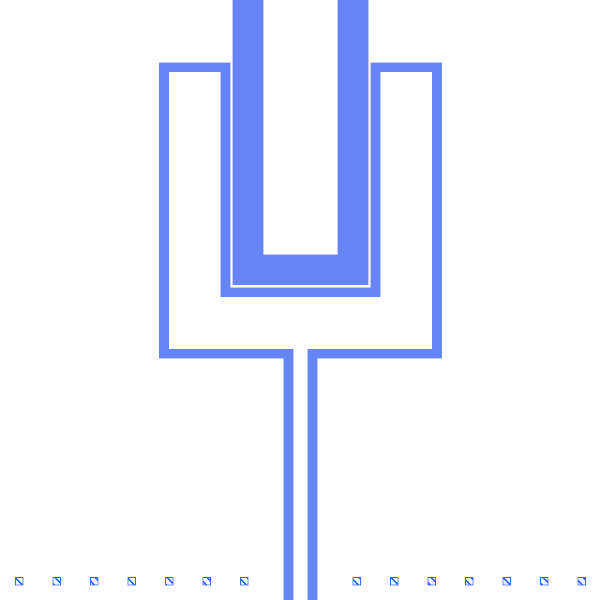

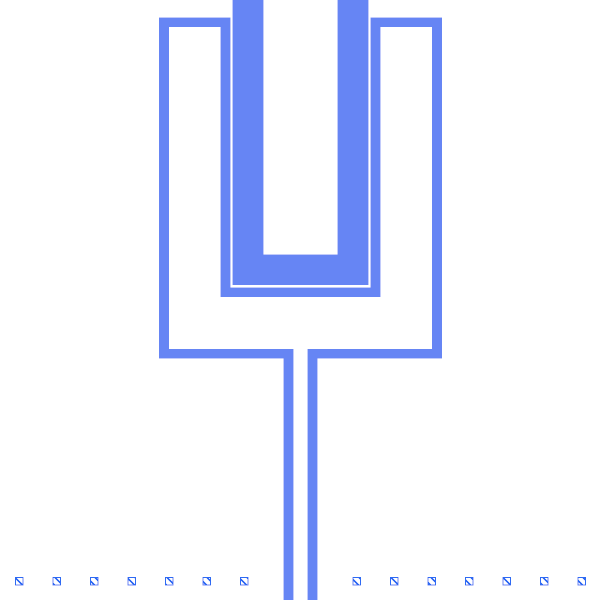

WindowsPath('examples/tutorials/img/t01_claw_after.png')

In [21]:
from quantcore_circuits.design import design_hash

d2 = Designer.load(DESIGN, live=LIVE, out="build/t01_chip12_rev1.oas")
d2["Q1"].set(connection_pads={"a": {**LB.D12_CLAW, "claw_length": "180um"}})
T.built(d2)
before = T.lom_params(results["Q1+R1"], ["Q1.f_q_GHz", "Q1.alpha_MHz", "R1.f_GHz", "R1.chi_MHz", "R1.kappa_MHz"])
after = T.lom_params(C.simulate_groups(d2, {"Q1+R1": ["Q1", "R1"]})["Q1+R1"], list(before))
T.md(T.before_after_md(before, after))
print("design hash:", design_hash(d.design), "→", design_hash(d2.design), "| DRC:",
      "clean" if T.drc(d2).ok else "ERRORS")
claw_box = (X0 - 450, Y0 + 1550, X0 - 50, Y0 + 1950)
T.snap(d, "claw_before", box=claw_box, size=(600, 600), width=300)
T.snap(d2, "claw_after", box=claw_box, size=(600, 600), width=300)

## 13 · Build and export

- **The design** is `examples/tutorials/designs/t01_chip12.json` (saved in section 10); `qcc build` rebuilds it.
- **Fab export** (`export_fab`): only the PDK fab layers, flat. Cheese: the build's own (here the PDK band, since
  the source had none; `cheese_source = "build"`); `cheese=False` writes none. Corners rounded (r ∝ the shortest
  dimension, ≤ 10 µm); `rounding=False` keeps them sharp. 3/0 is derived from the components and routes.
- **Cheese source** is a chip parameter: `chip={"cheese": "auto"}` (default: PDK band unless the design has its own),
  `"pdk"` (band always) or `"original"` (the design's own cheese, or none).
- **Simulation exports** never carry cheese; airbridges are dropped unless `airbridges=True` (`--airbridges`). This
  chip has no airbridges (Tutorial 3 has many).

In [22]:
import warnings
from quantcore_circuits.layouts.wafers.fab_export import export_fab

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    rep_fab = {}
    fab = export_fab(T.built(d), "build/t01_chip12_fab.oas", report=rep_fab)
    rep_plain = {}
    export_fab(T.built(d), "build/t01_chip12_fab_nocheese.oas", report=rep_plain, cheese=False, rounding=False)
T.md(T.fab_report_md(rep_fab, fab))
print(f"cheese=False, rounding=False: {rep_plain.get('cheese_holes', 0)} holes, cheese source "
      f"{rep_plain.get('cheese_source')}, M1 polygons {rep_plain['written'].get('M1')}")

`build/t01_chip12_fab.oas`: cheese **build** (14723 holes)

| fab layer | polygons |
|---|---|
| `CHIP_BOUNDARY` | 1 |
| `HSQ` | 28 |
| `JJ_BENT` | 9 |
| `JJ_STRAIGHT` | 9 |
| `M1` | 14765 |
| `M3` | 14727 |
| `MARKERS_ALIGN` | 36 |
| `MARKERS_DICING` | 4 |
| `SPACER_1` | 28 |
| `SPACER_2` | 28 |
| `SPACER_3` | 28 |

cheese=False, rounding=False: 0 holes, cheese source none, M1 polygons 42


**CLI equivalents** (from the repository root):

```bat
qcc build examples/tutorials/designs/t01_chip12.json --show          REM build (+ KLive)
qcc design drc examples/tutorials/designs/t01_chip12.json            REM the DRC of section 7
qcc circuit export examples/tutorials/designs/t01_chip12.json        REM LOM netlist → build/t01_chip12.circuit.json
qcc circuit simulate build/t01_chip12.circuit.json                   REM LOM simulation of the whole circuit
qcc sim build examples/tutorials/designs/t01_chip12.json -g Q1_R1 -a q3d_cmatrix
qcc hfss render examples/tutorials/designs/t01_chip12.json -g Q1_R1 -a eigenmode_epr --solve
qcc hfss solve build/jobs/t01_chip12_Q1_R1_q3d_cmatrix              REM solve an exported job (new -ng AEDT)
qcc hfss check build/jobs/t01_chip12_Q1_R1_q3d_cmatrix              REM read the .aedt back: stack, ports, nets
qcc mask examples/tutorials/designs/t01_chip12.json                  REM fab export (--no-cheese, --no-round)
```

## 14 · Snapshots

The full chip (PDK frame, pads at the edge, device ID), the direct pair, a SQUID's two trilayer junctions, a readout
short against the feedline, the fab export (cheese band, 3/0 keep-out), and the legacy notebook's own screenshot.

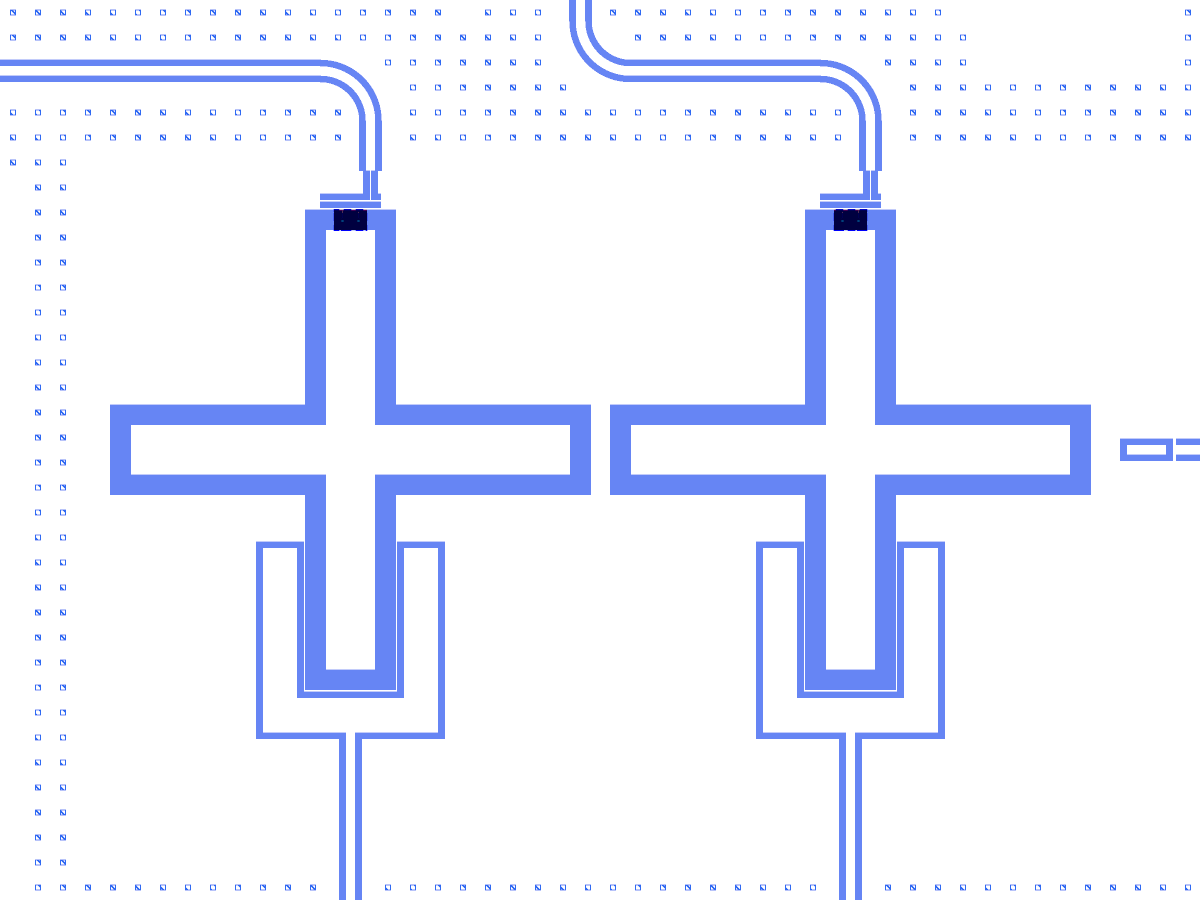

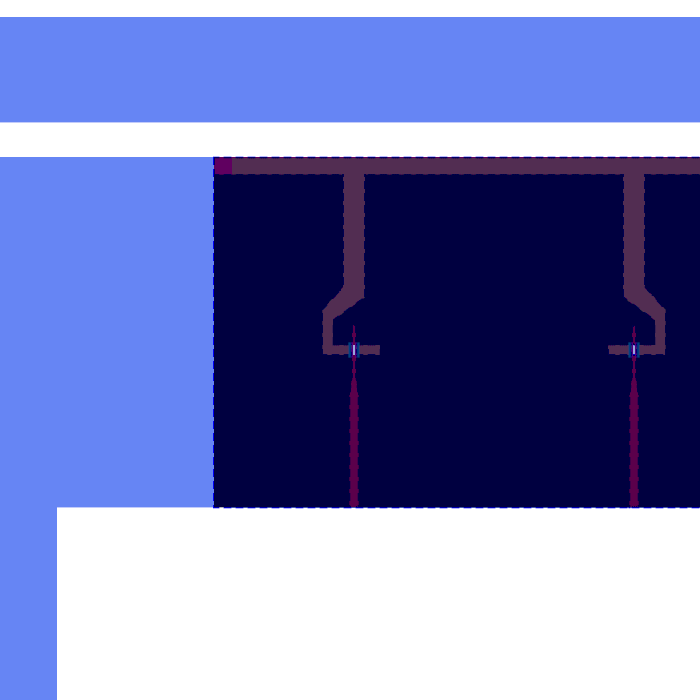

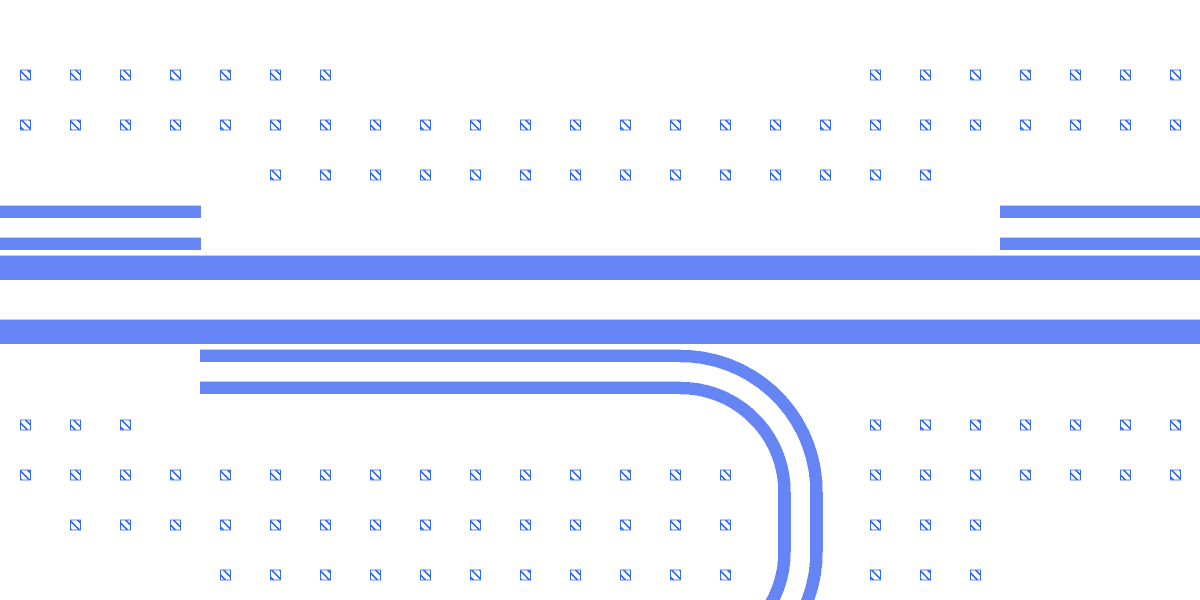

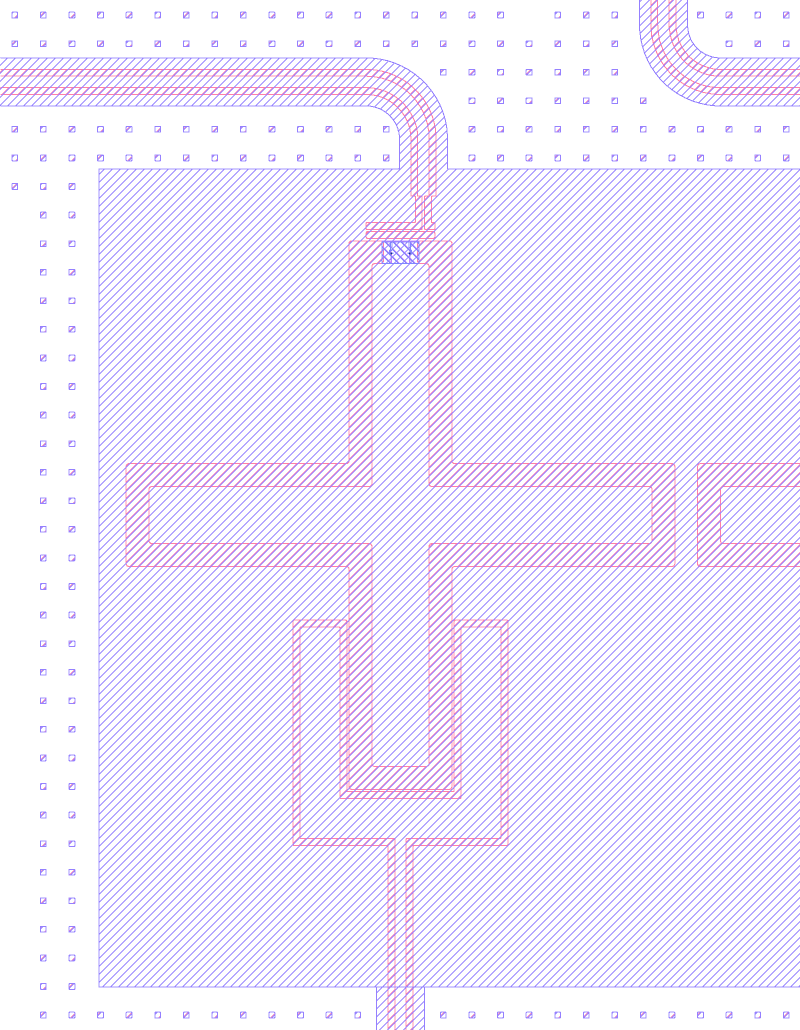

**Legacy (Quantum Metal) screenshot**, from the design notebook:

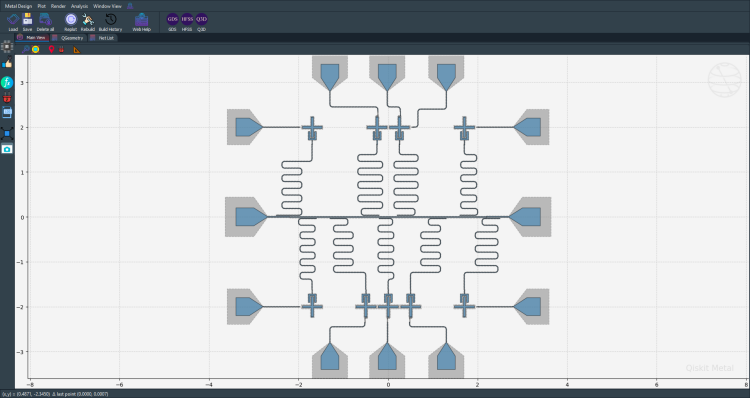

In [23]:
T.snap(d, "pair", box=at(-600, 1550) + at(600, 2450), size=(1200, 900), width=560)          # Q1–Q2 arm tips
T.snap(d, "squid", box=T.junction_box(d, "Q1", half=20), size=(700, 700), width=280)          # one of Q1's junctions
T.snap(d, "short", box=at(-300, -150) + at(300, 150), size=(1200, 600), width=560)          # R8 short at the line
T.snap(d, "fab_q1", box=at(-600, 1550) + at(100, 2450), size=(800, 1030), width=400, source=fab)
T.md("**Legacy (Quantum Metal) screenshot**, from the design notebook:")
display(T.Image(filename=str(ROOT / "docs/images/designs/legacy/d12_coupled_chip_legacy.png"), width=560))

## 15 · Summary

| | |
|---|---|
| **matches the source** | all 9 Xmons, 12 launchpads, 9 readouts (lengths to < 0.1 µm, couplers 36 µm off the line, shorts), 10 flux/drive lines through the legacy corner points |
| **PDK changes** | pads at 100 µm from the edge; trilayer junctions at R_n 45 kΩ; PDK cheese band; QCT frame and device ID |
| **DRC** | 0 errors; expected `dangling_port` warnings (bond pads, junction attachment points) |
| **open PDK design warnings** | none (the SQUIDs' device R_n is 45 kΩ; 90 kΩ per junction) |
| **LOM** | f_q ≈ 5.0 GHz, α ≈ −145 MHz; readouts 0.6–1.2 GHz below their bare λ/4 (claw loading); Q0/R0 hybridise; direct-pair J ≈ 30 MHz (rough C estimate) |
| **FEM** | stage 1, subset check (FEM only): `SIM_SUBSET` boxes, `Q1_q` / `Q1_R1e` eigenmodes, `Q1_Q2`; stage 2: their values in the whole netlist (the rest estimates) → LOM per pair vs FEM, J on FEM values, readout feedback → revision (DRC, fab); `FEM_WHOLE` (opt-in) fills from the whole-chip Q3D. 11 Q3D + 2 eigenmode jobs exported; `Q1_R1` Q3D (AEDT 2024 R1, 147 s, kept in `examples/tutorials/fem/`): C_g 2.1× the estimate, \|χ\| ≈ 6× on FEM values; workstation-sized eigenmode groups `Q1_q` (qubit, readout cut into a 50 Ω line) and `Q1_R1e` (qubit + readout, 100 µm margin); `Q1_Q2` Q3D → J on FEM values |
| **iterate** | claw 150 → 180 µm: χ and f_r move as expected; DRC still clean |

Next: **Tutorial 2** (`02_ibm_bowtie_5q.ipynb`), a chip whose couplings go through bus resonators.